In [2]:
#importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
#DOWNLOADING THE DATASET FROM KAGGLE
import kagglehub
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print(path)

Resuming download from 23068672 bytes (46087000 bytes left)...
Resuming download to C:\Users\Sakshi\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\3.archive (23068672/69155672) bytes left.


100%|██████████| 66.0M/66.0M [00:24<00:00, 1.90MB/s]

Extracting files...


C:\Users\Sakshi\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3


In [10]:
#SETTING UP THE PATH 
import pandas as pd, os
df = pd.read_csv(os.path.join(path, "creditcard.csv"))

#SAVING THE DATASET TO A LOCAL FILE
os.makedirs("../data/raw", exist_ok=True)
df.to_csv("../data/raw/creditcard.csv", index=False)

In [11]:
#LOADING THE DATASET AND INSPECTING IT
df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)                      # (284807, 31)
df.info()
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)
df.describe().T

(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


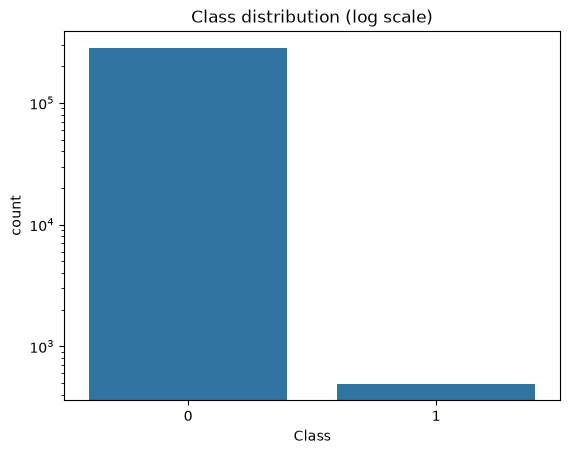

In [ ]:
#EXPLORATORY DATA ANALYSIS (EDA)

#1.Class imbalance
sns.countplot(x="Class", data=df)
plt.yscale("log"); plt.title("Class distribution (log scale)")  #IN THESE DATSETS THE IMBALANCE IS USUALLY EXTREME THAT'S WHY WE USE LOGARTHMIC SCALE TO VISUALIZE THE CLASS DISTRIBUTION
plt.show()

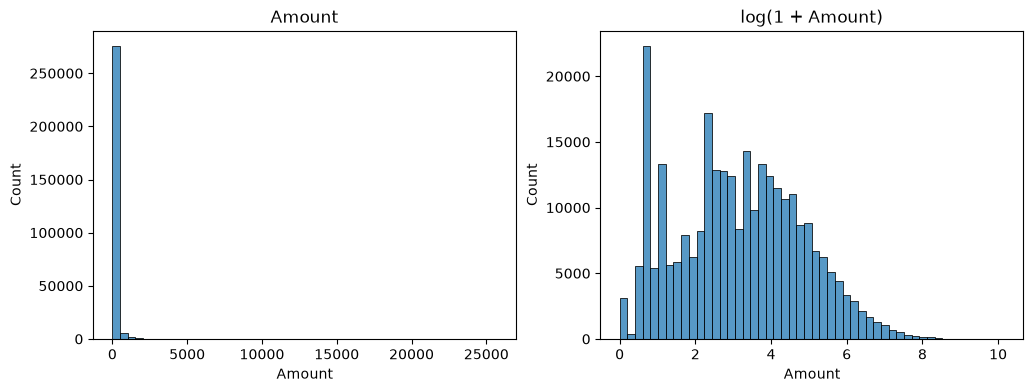

In [13]:
#2.Amount: RAW TRANSACTIONS ARE HEAVILY SKEWED, SO WE USE LOG-TRANSFORMATION FOR BETTER VISUALIZATION
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Amount"], bins=50, ax=ax[0]); ax[0].set_title("Amount") #PLOTS HISTOGRAM OF RAW TRANSACTION AMOUMNTS
sns.histplot(np.log1p(df["Amount"]), bins=50, ax=ax[1]); ax[1].set_title("log(1 + Amount)") #PLOTS HISTOGRAM OF LOG-CHANGED TRANSACTION AMOUNTS
plt.show()